# Unit 3 – Multiple Linear Regression
**Module:** Machine Learning (ML_PCOM7E)  |  **e-Portfolio activity:** Correlation and Regression (3 of 4)

**Aim:** predict a continuous outcome from several predictors, interpret coefficients, check multicollinearity (VIF) and compare feature subsets.

Dataset: *Diabetes* (scikit-learn, 442 patients, 10 baseline features, target = disease progression after one year).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
d=load_diabetes(as_frame=True); X,y=d.data,d.target
FEATURES=list(X.columns)      # <- try removing features, e.g. ['bmi','bp','s5']
Xtr,Xte,ytr,yte=train_test_split(X[FEATURES],y,test_size=.25,random_state=42)
m=LinearRegression().fit(Xtr,ytr); p=m.predict(Xte)
n,k=len(yte),len(FEATURES); r2=r2_score(yte,p)
print(f"Test R2={r2:.3f}  adjusted R2={1-(1-r2)*(n-1)/(n-k-1):.3f}  RMSE={mean_squared_error(yte,p)**.5:.2f}")
pd.Series(m.coef_,index=FEATURES).round(1).sort_values()

Test R2=0.485  adjusted R2=0.433  RMSE=53.37


s1    -918.5
sex   -242.0
s6      26.3
age     47.7
s3     117.0
s4     269.5
bp     381.6
s2     508.3
bmi    532.0
s5     695.8
dtype: float64

## Multicollinearity check (VIF > 5 is a warning, > 10 serious)

In [2]:
Xc=Xtr.assign(const=1.0)
vif=pd.Series([variance_inflation_factor(Xc.values,i) for i in range(len(FEATURES))],index=FEATURES).round(2).sort_values(ascending=False)
print(vif)

s1     54.30
s2     35.60
s3     13.84
s5      9.80
s4      9.32
bmi     1.53
s6      1.46
bp      1.42
sex     1.25
age     1.22
dtype: float64


## Experiment – compare feature subsets

                         R2  adj_R2    RMSE
all 10                0.485   0.433  53.370
bmi only              0.317   0.311  61.446
bmi+bp                0.355   0.343  59.710
bmi+bp+s5             0.502   0.488  52.462
no s1,s2 (collinear)  0.496   0.457  52.770


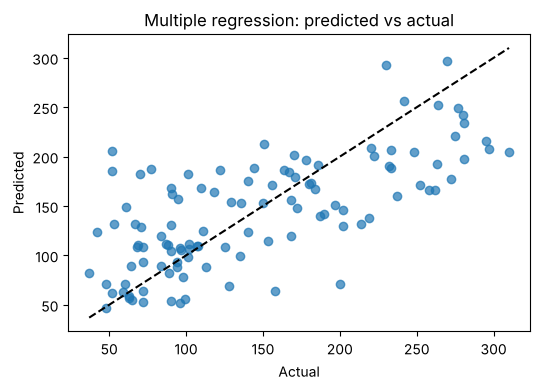

In [3]:
def evaluate(cols):
    a,b,c,e=train_test_split(X[cols],y,test_size=.25,random_state=42)
    mm=LinearRegression().fit(a,c); pr=mm.predict(b); nn,kk=len(e),len(cols); r=r2_score(e,pr)
    return r, 1-(1-r)*(nn-1)/(nn-kk-1), mean_squared_error(e,pr)**.5
sets={"all 10":FEATURES,"bmi only":["bmi"],"bmi+bp":["bmi","bp"],"bmi+bp+s5":["bmi","bp","s5"],"no s1,s2 (collinear)":[f for f in FEATURES if f not in("s1","s2")]}
res=pd.DataFrame({k:evaluate(v) for k,v in sets.items()},index=["R2","adj_R2","RMSE"]).T.round(3); print(res)
fig,ax=plt.subplots(figsize=(5.5,4)); ax.scatter(yte,p,alpha=.7); lim=[yte.min(),yte.max()]; ax.plot(lim,lim,"k--")
ax.set(xlabel="Actual",ylabel="Predicted",title="Multiple regression: predicted vs actual"); plt.tight_layout(); plt.savefig("fig_multireg.png",dpi=130); plt.show()

## Interpretation
* The model explains about 49% of the variance on unseen data (R² = 0.485); the rest is not captured by a linear combination of these ten features.
* BMI, blood pressure and the s5 serum measure carry most of the signal; a three-feature model (bmi, bp, s5) actually beats all ten on test R² (0.502 vs 0.485) and adjusted R² (0.488 vs 0.433).
* Features s1 and s2 (serum measurements) are highly collinear (VIF of 54 and 36), so their individual coefficients are unstable and should not be interpreted separately.
* Adjusted R² penalises unnecessary predictors, which is why the smaller models compare well.